In [7]:

from pathlib import Path
import pandas as pd
import numpy as np

FILE_PATH = Path("/kaggle/input/datasets/h7alasaleh/smoking/train.csv")

def load_dataset(path):
    suffix = path.suffix.lower()

    if suffix == ".csv":
        return pd.read_csv(path, sep=None, engine="python")

    elif suffix in [".xlsx", ".xls"]:
        return pd.read_excel(path)

    elif suffix == ".parquet":
        return pd.read_parquet(path)

    elif suffix == ".json":
        return pd.read_json(path)

    else:
        raise ValueError(f"Unsupported file format: {suffix}")


if not FILE_PATH.exists():
    raise FileNotFoundError(
        f"File not found: {FILE_PATH.resolve()}\n"
        "Please check FILE_PATH and the file name."
    )

df = load_dataset(FILE_PATH)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 100)

print("=" * 80)
print("1. FILE INFORMATION")
print("=" * 80)
print("File name:", FILE_PATH.name)
print("File location:", FILE_PATH.resolve())
print("File size (MB):", round(FILE_PATH.stat().st_size / (1024**2), 3))


print("\n" + "=" * 80)
print("2. DATASET OVERVIEW")
print("=" * 80)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Memory usage (MB):", round(df.memory_usage(deep=True).sum() / (1024**2), 3))

print("\nColumn names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

print("\nFirst 10 rows:")
print(df.head(10).to_string(index=False))

print("\nLast 5 rows:")
print(df.tail(5).to_string(index=False))


print("\n" + "=" * 80)
print("3. DATA TYPES AND NON-NULL VALUES")
print("=" * 80)

df.info()

print("\n" + "=" * 80)
print("4. MISSING VALUES")
print("=" * 80)

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

print(missing.to_string())

print("\nTotal missing cells:", int(df.isna().sum().sum()))


print("\n" + "=" * 80)
print("5. DUPLICATES AND CONSTANT COLUMNS")
print("=" * 80)

print("Duplicate rows:", int(df.duplicated().sum()))

print("Duplicate column names:",
      df.columns[df.columns.duplicated()].tolist())

constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("Constant columns:", constant_columns)

print("\n" + "=" * 80)
print("6. NUMERICAL SUMMARY")
print("=" * 80)

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

if numeric_cols:
    print(df[numeric_cols].describe().T.to_string())
else:
    print("No numerical columns found.")

print("\n" + "=" * 80)
print("7. CATEGORICAL SUMMARY")
print("=" * 80)

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

if categorical_cols:
    print(df[categorical_cols].describe().T.to_string())
else:
    print("No categorical/text columns found.")


print("\n" + "=" * 80)
print("8. UNIQUE VALUES IN EACH COLUMN")
print("=" * 80)

for col in df.columns:
    print(f"\nColumn: {col}")
    print("Data type:", df[col].dtype)
    print("Unique values count:", df[col].nunique(dropna=False))

    unique_values = df[col].dropna().unique()

    if len(unique_values) <= 20:
        print("Values:", unique_values.tolist())
    else:
        print("First 20 unique values:", unique_values[:20].tolist())


print("\n" + "=" * 80)
print("9. CATEGORY DISTRIBUTIONS")
print("=" * 80)

for col in df.columns:
    # الأعمدة ذات الفئات القليلة فقط
    if df[col].nunique(dropna=False) <= 15:
        print(f"\nColumn: {col}")
        print(
            df[col]
            .value_counts(dropna=False)
            .to_string()
        )


print("\n" + "=" * 80)
print("10. POSSIBLE SMOKING / TARGET COLUMNS")
print("=" * 80)

keywords = [
    "smok", "cigarette", "tobacco",
    "target", "label", "class",
    "heart", "disease", "cancer",
    "lung", "status"
]

candidate_cols = [
    col for col in df.columns
    if any(word in str(col).lower() for word in keywords)
]

print("Candidate columns:", candidate_cols)

for col in candidate_cols:
    print(f"\nDistribution of {col}:")
    print(df[col].value_counts(dropna=False).to_string())

print("\n" + "=" * 80)
print("11. NUMERICAL VALUE RANGES")
print("=" * 80)

for col in numeric_cols:
    print(
        f"{col}: min={df[col].min()}, "
        f"max={df[col].max()}, "
        f"unique={df[col].nunique()}"
    )


print("\n" + "=" * 80)
print("12. FINAL SUMMARY")
print("=" * 80)

print("Dataset shape:", df.shape)
print("Numerical columns:", numeric_cols)
print("Categorical/text columns:", categorical_cols)
print("Total missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Possible target columns:", candidate_cols)

print("\nInspection completed successfully.")


1. FILE INFORMATION
File name: train.csv
File location: /kaggle/input/datasets/h7alasaleh/smoking/train.csv
File size (MB): 49.243

2. DATASET OVERVIEW
Number of rows: 198240
Number of columns: 43
Memory usage (MB): 51.802

Column names:
1. age
2. height(cm)
3. weight(kg)
4. waist(cm)
5. eyesight(left)
6. eyesight(right)
7. hearing(left)
8. hearing(right)
9. systolic
10. relaxation
11. fasting blood sugar
12. Cholesterol
13. triglyceride
14. HDL
15. LDL
16. hemoglobin
17. Urine protein
18. serum creatinine
19. AST
20. ALT
21. Gtp
22. dental caries
23. smoking
24. cardiovascular_risk_score
25. blood_pressure_variation
26. bmi
27. waist_to_height_ratio
28. estimated_gfr
29. cardiovascular_health_score
30. average_eyesight
31. average_hearing
32. cholesterol_ratio
33. liver_enzyme_ratio
34. fitness_level_Fit
35. fitness_level_Not Fit
36. bmi_category_Normal Weight
37. bmi_category_Obese
38. bmi_category_Overweight
39. bmi_category_Underweight
40. blood_pressure_category_Elevated
41. blood

In [8]:
print("Smoking distribution:")
print(df["smoking"].value_counts(dropna=False))

print("\nSmoking percentages:")
print((df["smoking"].value_counts(normalize=True) * 100).round(2))

print("\nCorrelation with smoking:")
numeric_corr = df.corr(numeric_only=True)["smoking"].drop("smoking")
print(numeric_corr.reindex(
    numeric_corr.abs().sort_values(ascending=False).index
).round(3))

Smoking distribution:
smoking
0.0    114269
1.0     83971
Name: count, dtype: int64

Smoking percentages:
smoking
0.0    57.64
1.0    42.36
Name: proportion, dtype: float64

Correlation with smoking:
hemoglobin                                      0.441
height(cm)                                      0.437
weight(kg)                                      0.343
triglyceride                                    0.315
Gtp                                             0.278
serum creatinine                                0.258
waist(cm)                                       0.257
HDL                                            -0.254
liver_enzyme_ratio                              0.245
cholesterol_ratio                               0.213
age                                            -0.198
ALT                                             0.138
bmi                                             0.136
estimated_gfr                                  -0.131
average_eyesight                            

In [9]:

import pandas as pd
from pathlib import Path

FILE_PATH = Path("/kaggle/input/datasets/h7alasaleh/smoking/train.csv")
df = pd.read_csv(FILE_PATH)

print("Original shape:", df.shape)

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df.shape)
print("\nTarget distribution:")
print(df["smoking"].value_counts())
print("\nMissing values:", df.isnull().sum().sum())

# Original health indicators for the first classification experiment
features = [
    "age",
    "height(cm)",
    "weight(kg)",
    "waist(cm)",
    "eyesight(left)",
    "eyesight(right)",
    "hearing(left)",
    "hearing(right)",
    "systolic",
    "relaxation",
    "fasting blood sugar",
    "Cholesterol",
    "triglyceride",
    "HDL",
    "LDL",
    "hemoglobin",
    "Urine protein",
    "serum creatinine",
    "AST",
    "ALT",
    "Gtp",
    "dental caries"
]

X = df[features].copy()
y = df["smoking"].astype(int)

print("\nNumber of features:", len(features))
print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeature data types:")
print(X.dtypes)

Original shape: (198240, 43)
Shape after removing duplicates: (192723, 43)

Target distribution:
smoking
0.0    110812
1.0     81911
Name: count, dtype: int64

Missing values: 0

Number of features: 22
X shape: (192723, 22)
y shape: (192723,)

Feature data types:
age                      int64
height(cm)               int64
weight(kg)               int64
waist(cm)              float64
eyesight(left)         float64
eyesight(right)        float64
hearing(left)            int64
hearing(right)           int64
systolic                 int64
relaxation               int64
fasting blood sugar      int64
Cholesterol              int64
triglyceride             int64
HDL                      int64
LDL                      int64
hemoglobin             float64
Urine protein            int64
serum creatinine       float64
AST                      int64
ALT                      int64
Gtp                      int64
dental caries            int64
dtype: object


Training rows: 154178
Testing rows: 38545

CLASSIFICATION RESULTS
       experiment           task  accuracy  precision  recall  f1_score  silhouette_score
Majority Baseline Classification    0.5750     0.0000  0.0000    0.0000               NaN
    Random Forest Classification    0.7717     0.7021  0.8039    0.7496               NaN


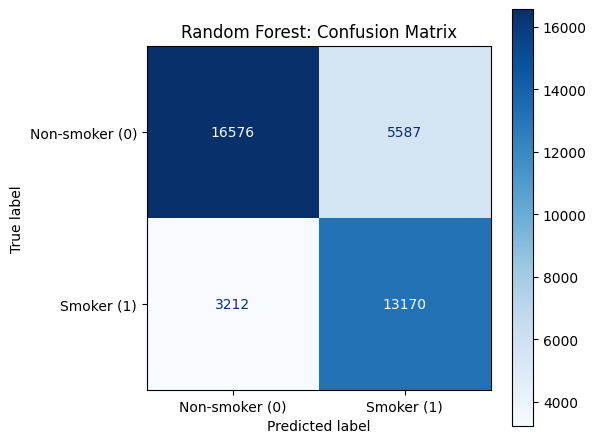

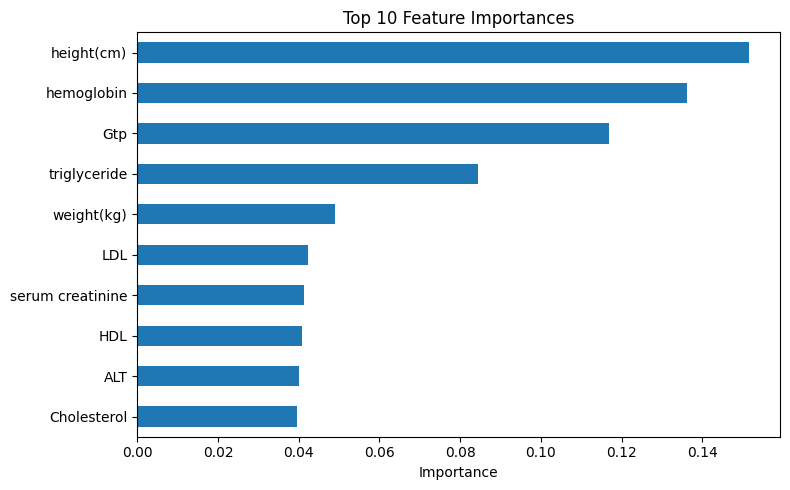


CLUSTERING RESULTS
Number of clusters: 3
Silhouette score: 0.1561

CLUSTER SUMMARY
         people  smoking_rate  mean_age  mean_hemoglobin  mean_triglyceride  smoking_rate_percent
cluster                                                                                          
0         16994         0.617    40.779           15.591            153.350                61.704
1         11979         0.167    47.953           13.630             91.620                16.746
2          1027         0.331    59.586           14.342            117.588                33.106


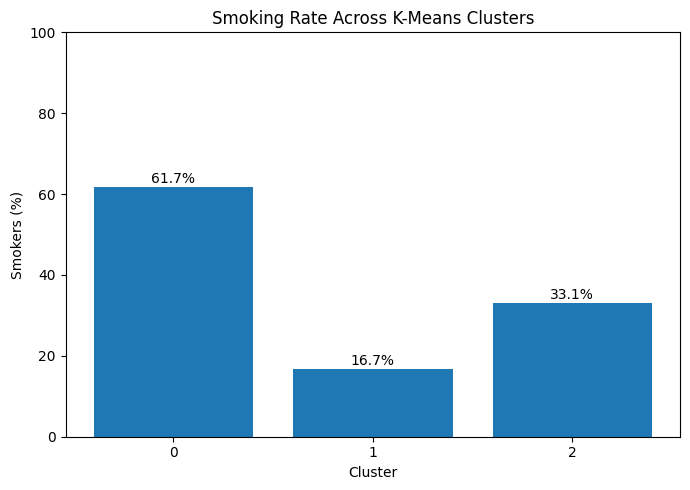


Saved results.csv
Figures saved in: /kaggle/working/figures


In [10]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
    silhouette_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# --------------------------------------------------
# 1. Prepare data
# --------------------------------------------------
os.makedirs("figures", exist_ok=True)

X = df[features].copy()
y = df["smoking"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

results = []

# --------------------------------------------------
# 2. Baseline classification
# --------------------------------------------------
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

results.append({
    "experiment": "Majority Baseline",
    "task": "Classification",
    "accuracy": accuracy_score(y_test, baseline_pred),
    "precision": precision_score(y_test, baseline_pred, zero_division=0),
    "recall": recall_score(y_test, baseline_pred, zero_division=0),
    "f1_score": f1_score(y_test, baseline_pred, zero_division=0),
    "silhouette_score": np.nan
})

# --------------------------------------------------
# 3. Random Forest classification
# --------------------------------------------------
rf = RandomForestClassifier(
    n_estimators=120,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

results.append({
    "experiment": "Random Forest",
    "task": "Classification",
    "accuracy": accuracy_score(y_test, rf_pred),
    "precision": precision_score(y_test, rf_pred, zero_division=0),
    "recall": recall_score(y_test, rf_pred, zero_division=0),
    "f1_score": f1_score(y_test, rf_pred, zero_division=0),
    "silhouette_score": np.nan
})

print("\nCLASSIFICATION RESULTS")
print(pd.DataFrame(results).round(4).to_string(index=False))

# Confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred,
    display_labels=["Non-smoker (0)", "Smoker (1)"],
    cmap="Blues",
    ax=ax
)
ax.set_title("Random Forest: Confusion Matrix")
fig.tight_layout()
fig.savefig("figures/confusion_matrix.png", dpi=150)
plt.show()

# Feature importance
importance = pd.Series(
    rf.feature_importances_,
    index=features
).sort_values(ascending=True).tail(10)

fig, ax = plt.subplots(figsize=(8, 5))
importance.plot(kind="barh", ax=ax)
ax.set_title("Top 10 Feature Importances")
ax.set_xlabel("Importance")
fig.tight_layout()
fig.savefig("figures/feature_importance.png", dpi=150)
plt.show()

# --------------------------------------------------
# 4. Clustering: K-Means
#    Smoking is NOT used to create clusters.
# --------------------------------------------------
cluster_features = features

# Use a reproducible sample to keep clustering practical
cluster_df = df.sample(
    n=min(30000, len(df)),
    random_state=42
).copy()

X_cluster = cluster_df[cluster_features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_df["cluster"] = kmeans.fit_predict(X_scaled)

# Silhouette score on a subset for speed
silhouette = silhouette_score(
    X_scaled,
    cluster_df["cluster"],
    sample_size=min(3000, len(cluster_df)),
    random_state=42
)

print("\nCLUSTERING RESULTS")
print("Number of clusters:", cluster_df["cluster"].nunique())
print("Silhouette score:", round(silhouette, 4))

# Compare smoking proportions after clustering
cluster_summary = cluster_df.groupby("cluster").agg(
    people=("smoking", "size"),
    smoking_rate=("smoking", "mean"),
    mean_age=("age", "mean"),
    mean_hemoglobin=("hemoglobin", "mean"),
    mean_triglyceride=("triglyceride", "mean")
)

cluster_summary["smoking_rate_percent"] = (
    cluster_summary["smoking_rate"] * 100
)

print("\nCLUSTER SUMMARY")
print(cluster_summary.round(3).to_string())

results.append({
    "experiment": "K-Means (k=3)",
    "task": "Clustering",
    "accuracy": np.nan,
    "precision": np.nan,
    "recall": np.nan,
    "f1_score": np.nan,
    "silhouette_score": silhouette
})

# Plot smoking rate by cluster
fig, ax = plt.subplots(figsize=(7, 5))
rates = cluster_summary["smoking_rate_percent"]
bars = ax.bar(rates.index.astype(str), rates.values)

ax.set_title("Smoking Rate Across K-Means Clusters")
ax.set_xlabel("Cluster")
ax.set_ylabel("Smokers (%)")
ax.set_ylim(0, 100)

for bar, value in zip(bars, rates.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center"
    )

fig.tight_layout()
fig.savefig("figures/cluster_smoking_rate.png", dpi=150)
plt.show()

# --------------------------------------------------
# 5. Save experiment summary
# --------------------------------------------------
results_df = pd.DataFrame(results)
results_df.to_csv("results.csv", index=False)

print("\nSaved results.csv")
print("Figures saved in:", os.path.abspath("figures"))
